# Placement Comparison Analysis
LLM-as-a-judge pairwise comparisons between the **semantic** ad placement and three static baselines (**first**, **middle**, **last**).
Each (query, ad, baseline) has one judgment, with the semantic response as response 1.

1. **Sample** - what was scored.
2. **Win rate** - semantic win rate per baseline, with 95% Wilson intervals.
3. **Confidence** - win rate by the judge's stated confidence.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#898781",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
SEMANTIC = "#2a78d6"
CONFIDENCE_COLORS = {"low": "#86b6ef", "medium": "#2a78d6", "high": "#104281"}
BASELINES = ["first", "middle", "last"]


def wilson(successes, n, z=1.96):
    """95% Wilson score interval for a proportion, as (low, high) in [0, 1]."""
    successes, n = np.asarray(successes, float), np.asarray(n, float)
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def rate_table(frame, by, outcome):
    """Rate of a boolean `outcome` per group, in %, with Wilson 95% CI and n."""
    out = frame.groupby(by)[outcome].agg(wins="sum", n="count").reset_index()
    low, high = wilson(out["wins"], out["n"])
    out["rate_%"], out["ci_low_%"], out["ci_high_%"] = 100 * out["wins"] / out["n"], 100 * low, 100 * high
    return out


df = pd.read_csv("../../../data/evaluation/ad_placement_eval/placement_comparison_scores.csv")
df = df[~df["is_swapped"]].reset_index(drop=True)  # one judgment per (query, ad, baseline): semantic as response 1
df["baseline_pos"] = df["pos_2"]
df["semantic_won"] = df["winner_pos"] == "semantic"

## 1. Sample

In [2]:
print(f"{len(df):,} judgments over {df['query_id'].nunique():,} queries")
print("duplicate (query, ad, baseline) rows:", df.duplicated(["query_id", "ad_id", "baseline_pos"]).sum())
display(df["baseline_pos"].value_counts().reindex(BASELINES).rename("judgments").to_frame())
display(df["confidence"].value_counts().rename("judgments").to_frame())

37,888 judgments over 12,630 queries
duplicate (query, ad, baseline) rows: 0


,judgments
baseline_pos,
first,12630
middle,12629
last,12629


,judgments
confidence,
high,30992
low,6391
medium,505


## 2. Win rate
Share of judgments that semantic won against each baseline.

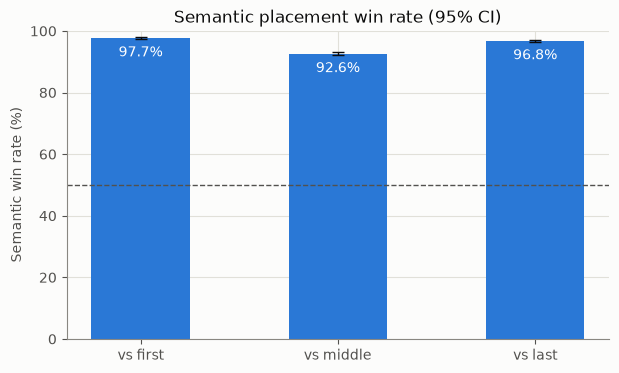

,wins,n,rate_%,ci_low_%,ci_high_%
baseline_pos,,,,,
first,12345,12630,97.74,97.47,97.99
middle,11698,12629,92.63,92.16,93.07
last,12226,12629,96.81,96.49,97.10


In [3]:
win_rates = rate_table(df, "baseline_pos", "semantic_won").set_index("baseline_pos").reindex(BASELINES)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(BASELINES))
ax.bar(x, win_rates["rate_%"], width=0.5, color=SEMANTIC)
ax.errorbar(x, win_rates["rate_%"],
            yerr=[win_rates["rate_%"] - win_rates["ci_low_%"], win_rates["ci_high_%"] - win_rates["rate_%"]],
            fmt="none", ecolor="#0b0b0b", capsize=4, linewidth=1)
for xi, rate in zip(x, win_rates["rate_%"]):
    ax.text(xi, rate - 6, f"{rate:.1f}%", ha="center", color="#ffffff")
ax.axhline(50, color="#52514e", linestyle="--", linewidth=1)
ax.set_xticks(x, [f"vs {b}" for b in BASELINES])
ax.set(ylim=(0, 100), ylabel="Semantic win rate (%)", title="Semantic placement win rate (95% CI)")
plt.show()

display(win_rates.round(2))

## 3. Win rate by confidence
Semantic win rate split by the judge's stated confidence. Check `n`: a level with few judgments gets a wide interval.

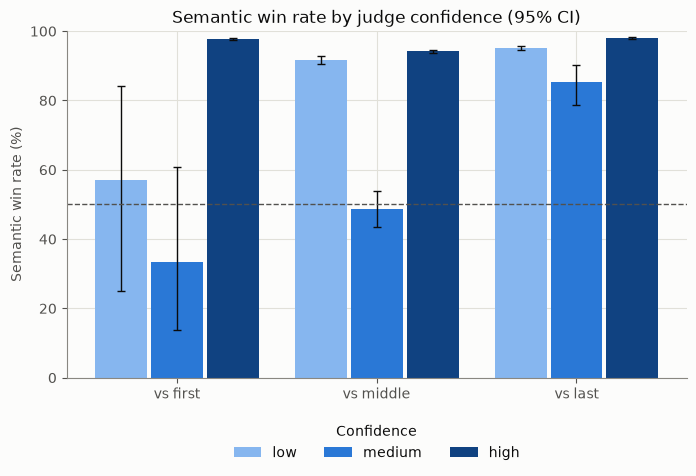

,baseline_pos,confidence,wins,n,rate_%,ci_low_%,ci_high_%
0,first,high,12337,12611,97.83,97.56,98.07
1,first,low,4,7,57.14,25.05,84.18
2,first,medium,4,12,33.33,13.81,60.94
3,last,high,7821,7984,97.96,97.62,98.25
4,last,low,4283,4502,95.14,94.47,95.73
5,last,medium,122,143,85.31,78.59,90.19
6,middle,high,9800,10397,94.26,93.79,94.69
7,middle,low,1728,1882,91.82,90.49,92.97
8,middle,medium,170,350,48.57,43.38,53.79


In [4]:
CONFIDENCE = ["low", "medium", "high"]
conf = rate_table(df, ["baseline_pos", "confidence"], "semantic_won")

fig, ax = plt.subplots(figsize=(8, 4.5))
width = 0.26
for i, level in enumerate(CONFIDENCE):
    sub = conf[conf["confidence"] == level].set_index("baseline_pos").reindex(BASELINES)
    xs = np.arange(len(BASELINES)) + (i - 1) * (width + 0.02)
    ax.bar(xs, sub["rate_%"], width=width, color=CONFIDENCE_COLORS[level], label=level)
    ax.errorbar(xs, sub["rate_%"], yerr=[sub["rate_%"] - sub["ci_low_%"], sub["ci_high_%"] - sub["rate_%"]],
                fmt="none", ecolor="#0b0b0b", capsize=3, linewidth=1)
ax.axhline(50, color="#52514e", linestyle="--", linewidth=1)
ax.set_xticks(range(len(BASELINES)), [f"vs {b}" for b in BASELINES])
ax.set(ylim=(0, 100), ylabel="Semantic win rate (%)", title="Semantic win rate by judge confidence (95% CI)")
ax.legend(title="Confidence", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.show()

display(conf.round(2))

## Findings (2026-11-05: 12,630 queries, 37,888 judgments)
- **Semantic wins 92.6-97.7% of judgments:** **97.7%** vs first, **92.6%** vs middle, **96.8%** vs last
  (95% CIs within about ±0.5 pp).
- **Middle is the strongest baseline** (lowest semantic win rate); first is the weakest.
- **The judge is mostly confident:** 82% of judgments are "high", and high-confidence win rates match the overall ones
  (97.8% / 94.3% / 98.0%).
- **Low and medium confidence vs first are rare** (7 and 12 judgments), so their intervals are wide. Medium-confidence
  judgments vs middle are close to even (48.6%, n=350).